In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import os

os.chdir("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Clustering/")

In [16]:
df= pd.read_csv("fincas_data.csv", sep=",")
df.head()

,Finca,Individuos,Especies,Hectareas,Animales,Comunidad,Mercado,Berger-Parker,Gini-Simpson,Shannon,Margalef,Ganancia
0,Finca1,1367,40,1.27,1,Puerto Tejada,1,0.02,1.00,4.04,5.34,4349.73
1,Finca2,206,18,0.22,0,Alegrias,0,0.06,0.95,1.37,3.18,417.30
2,Finca3,1192,23,0.94,0,Puerto Tejada,0,0.04,0.94,1.91,3.12,3486.80
3,Finca4,1341,11,1.36,0,Alegrias,0,0.09,0.92,0.77,1.19,4108.62
4,Finca5,779,21,0.77,0,Agua Azul,0,0.06,0.96,1.82,2.82,2412.38


In [17]:
num= df.select_dtypes(["float64", "int64"]).columns
df2= df[num]

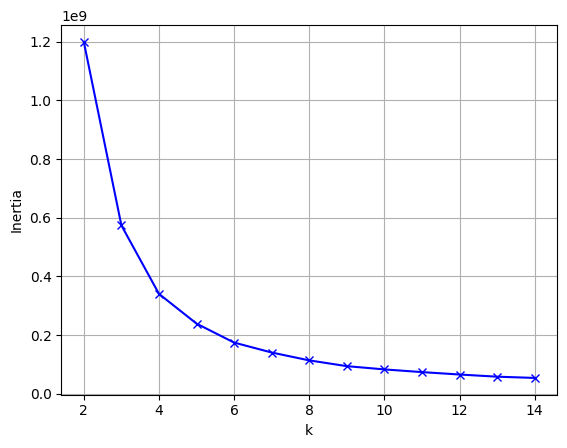

In [18]:
sum_squared_distances= []
K= range(2,15)

for k in K:
    km= KMeans(n_clusters=k)
    km= km.fit(df2)
    sum_squared_distances.append(km.inertia_)

plt.plot(K, sum_squared_distances, "bx-")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.grid()

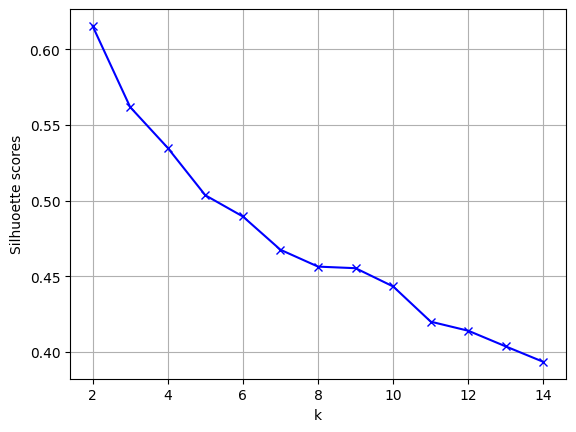

In [19]:
silhuoette_scores= []
K= range(2,15)

for k in K:
    km= KMeans(n_clusters=k)
    km= km.fit(df2)
    y= km.predict(df2)
    silhuoette_scores.append(silhouette_score(df2,y))

plt.plot(K, silhuoette_scores, "bx-")
plt.xlabel("k")
plt.ylabel("Silhuoette scores")
plt.grid()

In [9]:
pca= PCA(n_components= 2)
X_reduced= pca.fit_transform(df2)

kmeans= KMeans(n_clusters=2, random_state=0)
y_pred= kmeans.fit_predict(df2)

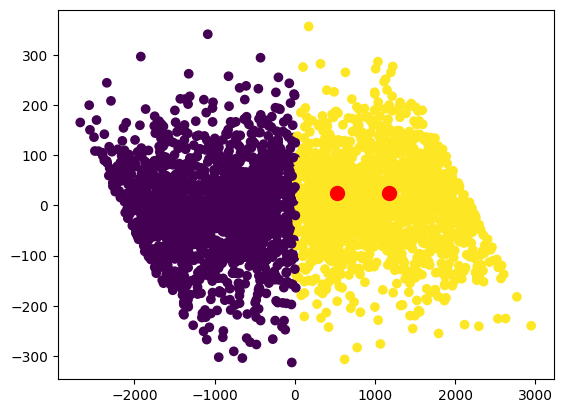

In [20]:
plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=y_pred, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=100, c='red', label='Centroides')

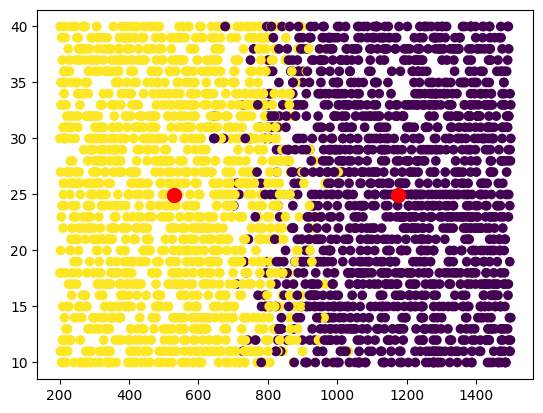

In [21]:
#SIN PCA

plt.scatter(df2.iloc[:, 0], df2.iloc[:, 1], c=y_pred, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=100, c='red', label='Centroides')

In [23]:
df["cluster"]= y_pred
df.head()

,Finca,Individuos,Especies,Hectareas,Animales,Comunidad,Mercado,Berger-Parker,Gini-Simpson,Shannon,Margalef,Ganancia,cluster
0,Finca1,1367,40,1.27,1,Puerto Tejada,1,0.02,1.00,4.04,5.34,4349.73,0
1,Finca2,206,18,0.22,0,Alegrias,0,0.06,0.95,1.37,3.18,417.30,1
2,Finca3,1192,23,0.94,0,Puerto Tejada,0,0.04,0.94,1.91,3.12,3486.80,0
3,Finca4,1341,11,1.36,0,Alegrias,0,0.09,0.92,0.77,1.19,4108.62,0
4,Finca5,779,21,0.77,0,Agua Azul,0,0.06,0.96,1.82,2.82,2412.38,1


In [24]:
df.to_csv("fincas_data_cluster.csv", index=False)